In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

ROOT_DIR = Path.cwd()

if ROOT_DIR.name == "notebooks":
    ROOT_DIR = ROOT_DIR.parent

DATA_PATH = (
    ROOT_DIR
    / "data"
    / "raw"
    / "transaction_fraud_risk_advanced_dataset.csv"
)

FIGURE_DIR = ROOT_DIR / "outputs" / "figures"
TABLE_DIR = ROOT_DIR / "outputs" / "tables"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Project initialized successfully!")

Project initialized successfully!


In [2]:
df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)

display(df.head())

display(df.info())

Dataset Shape: (3000, 25)


,transaction_id,hour,day_of_week,transaction_amount,distance_from_usual_location_km,transactions_last_1h,transactions_last_24h,account_age_days,failed_logins_24h,prior_chargebacks,...,card_presence,channel,country,device_type,merchant_category,authentication_level,new_device,billing_address_mismatch,customer_tier,fraud
0,TXN5000001,20,0,35.01,47.93,6,12,783,0,0,...,Not present,E-commerce,Sri Lanka,iOS,Grocery,Standard,0,1,Basic,1
1,TXN5000002,4,1,29.66,78.02,2,6,564,0,0,...,Not present,POS,UK,macOS,Grocery,Strong,0,1,Basic,0
2,TXN5000003,0,4,46.05,21.39,5,10,1618,0,0,...,Present,E-commerce,Sri Lanka,Android,Grocery,Standard,0,0,Gold,0
3,TXN5000004,15,4,77.02,95.29,4,10,1433,1,0,...,Present,E-commerce,Sri Lanka,Other,Grocery,Strong,0,0,Basic,0
4,TXN5000005,8,3,187.65,6.08,1,10,50,0,0,...,Not present,POS,Sri Lanka,Android,Grocery,Standard,0,0,Basic,0


<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 25 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   transaction_id                   3000 non-null   str    
 1   hour                             3000 non-null   int64  
 2   day_of_week                      3000 non-null   int64  
 3   transaction_amount               2947 non-null   float64
 4   distance_from_usual_location_km  2925 non-null   float64
 5   transactions_last_1h             3000 non-null   int64  
 6   transactions_last_24h            3000 non-null   int64  
 7   account_age_days                 3000 non-null   int64  
 8   failed_logins_24h                3000 non-null   int64  
 9   prior_chargebacks                3000 non-null   int64  
 10  device_age_days                  3000 non-null   int64  
 11  merchant_risk_score              2940 non-null   float64
 12  ip_risk_score                  

None

In [3]:
fraud_counts = df["fraud"].value_counts()

fraud_percentage = (
    df["fraud"].value_counts(normalize=True) * 100
)

print("Fraud Counts:")
print(fraud_counts)

print("\nFraud Percentages:")
print(fraud_percentage)

Fraud Counts:
fraud
0    2636
1     364
Name: count, dtype: int64

Fraud Percentages:
fraud
0    87.866667
1    12.133333
Name: proportion, dtype: float64


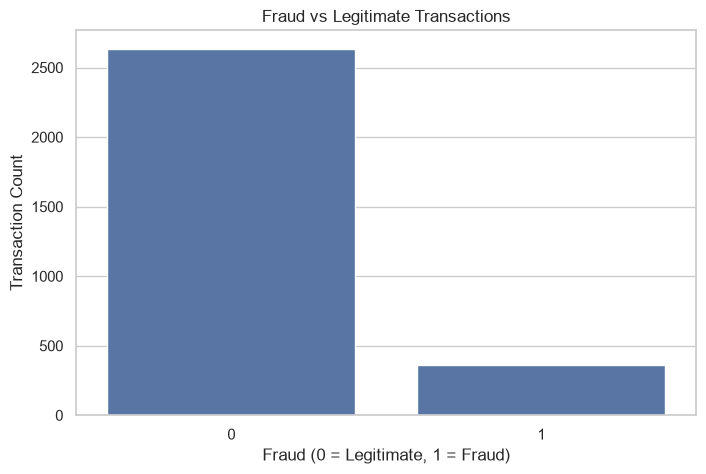

In [4]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="fraud"
)

plt.title("Fraud vs Legitimate Transactions")

plt.xlabel("Fraud (0 = Legitimate, 1 = Fraud)")

plt.ylabel("Transaction Count")

plt.savefig(
    FIGURE_DIR / "01_fraud_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

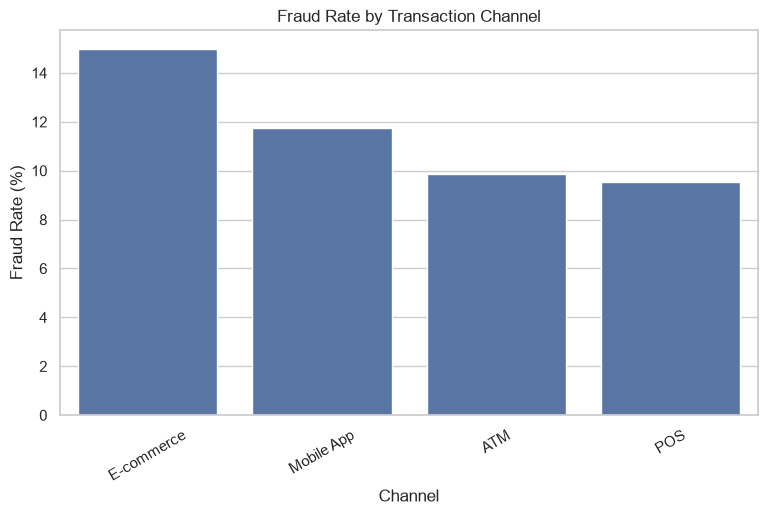

In [5]:
channel_fraud = (
    df.groupby("channel")["fraud"]
    .mean()
    .sort_values(ascending=False)
    * 100
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=channel_fraud.index,
    y=channel_fraud.values
)

plt.title("Fraud Rate by Transaction Channel")

plt.xlabel("Channel")

plt.ylabel("Fraud Rate (%)")

plt.xticks(rotation=30)

plt.savefig(
    FIGURE_DIR / "02_fraud_by_channel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

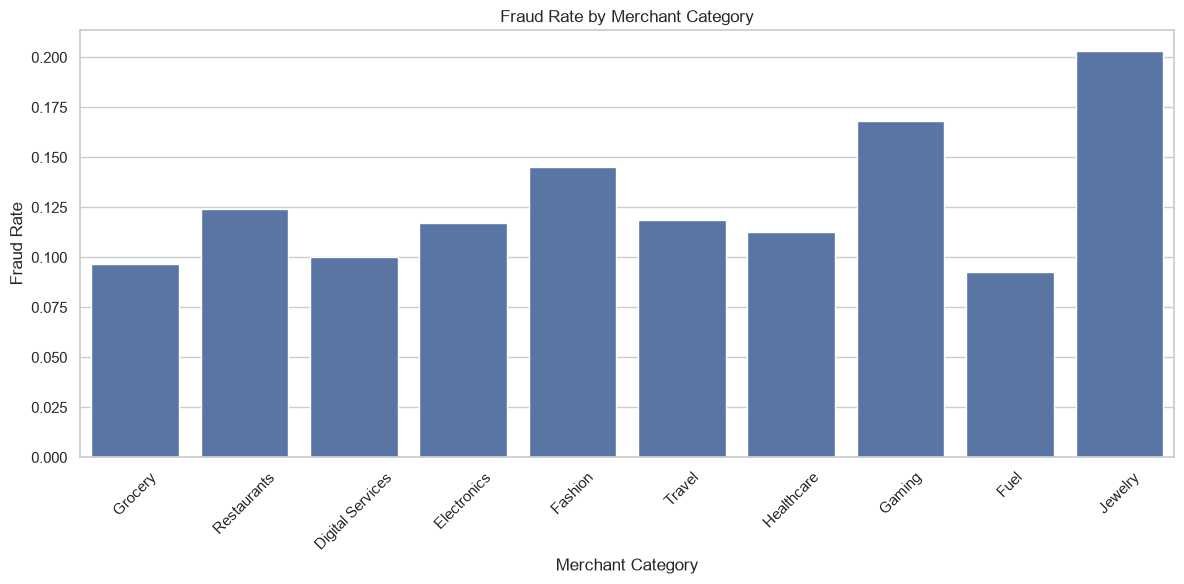

In [6]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="merchant_category",
    y="fraud",
    errorbar=None
)

plt.title("Fraud Rate by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Fraud Rate")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(FIGURE_DIR / "03_merchant_fraud.png", dpi=300)
plt.show()

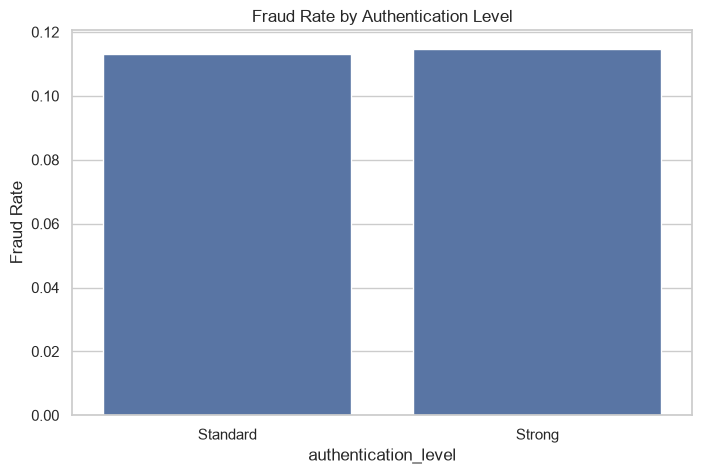

In [7]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="authentication_level",
    y="fraud",
    errorbar=None
)

plt.title("Fraud Rate by Authentication Level")
plt.ylabel("Fraud Rate")

plt.savefig(FIGURE_DIR / "04_authentication_fraud.png", dpi=300)
plt.show()

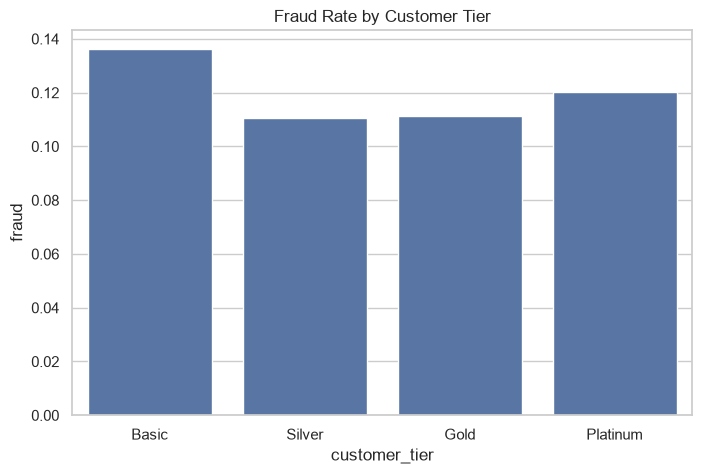

In [8]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="customer_tier",
    y="fraud",
    errorbar=None,
    order=["Basic", "Silver", "Gold", "Platinum"]
)

plt.title("Fraud Rate by Customer Tier")
plt.savefig(FIGURE_DIR / "05_customer_tier.png", dpi=300)
plt.show()

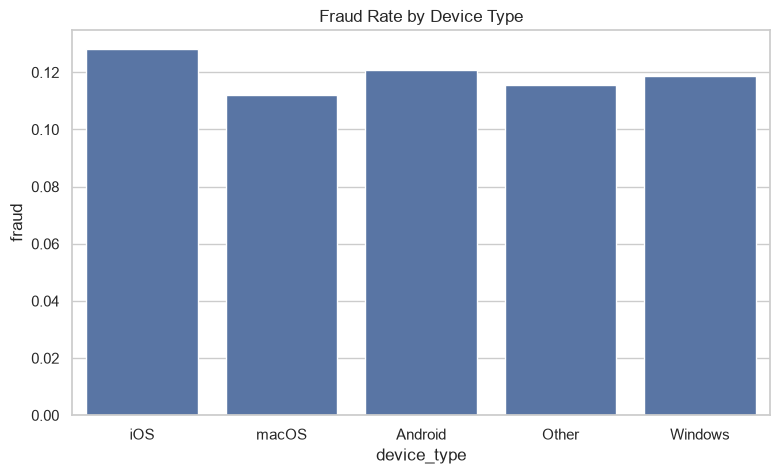

In [9]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="device_type",
    y="fraud",
    errorbar=None
)

plt.title("Fraud Rate by Device Type")

plt.savefig(FIGURE_DIR / "06_device_type.png", dpi=300)
plt.show()

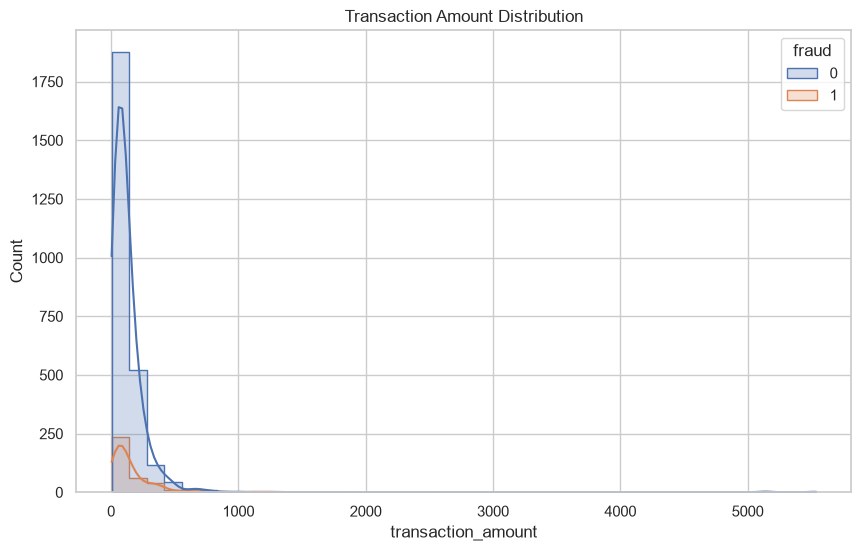

In [10]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="transaction_amount",
    hue="fraud",
    bins=40,
    kde=True,
    element="step"
)

plt.title("Transaction Amount Distribution")

plt.savefig(FIGURE_DIR / "07_amount_distribution.png", dpi=300)
plt.show()

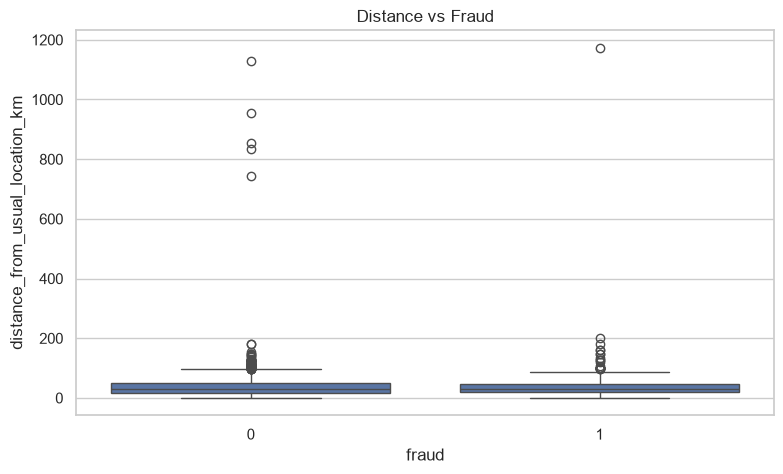

In [11]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="fraud",
    y="distance_from_usual_location_km"
)

plt.title("Distance vs Fraud")

plt.savefig(FIGURE_DIR / "08_distance_fraud.png", dpi=300)
plt.show()

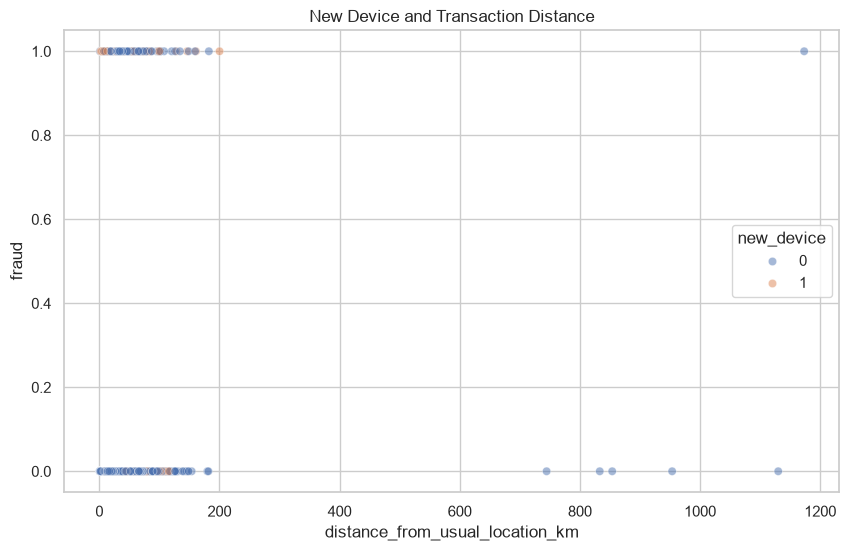

In [12]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="distance_from_usual_location_km",
    y="fraud",
    hue="new_device",
    alpha=0.5
)

plt.title("New Device and Transaction Distance")

plt.savefig(FIGURE_DIR / "09_device_distance.png", dpi=300)
plt.show()

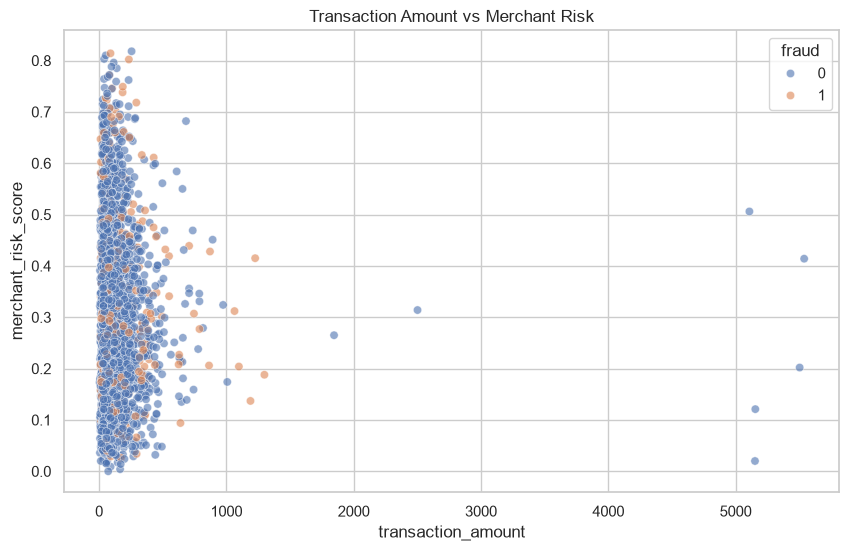

In [13]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="transaction_amount",
    y="merchant_risk_score",
    hue="fraud",
    alpha=0.6
)

plt.title("Transaction Amount vs Merchant Risk")

plt.savefig(FIGURE_DIR / "10_amount_merchant_interaction.png", dpi=300)
plt.show()


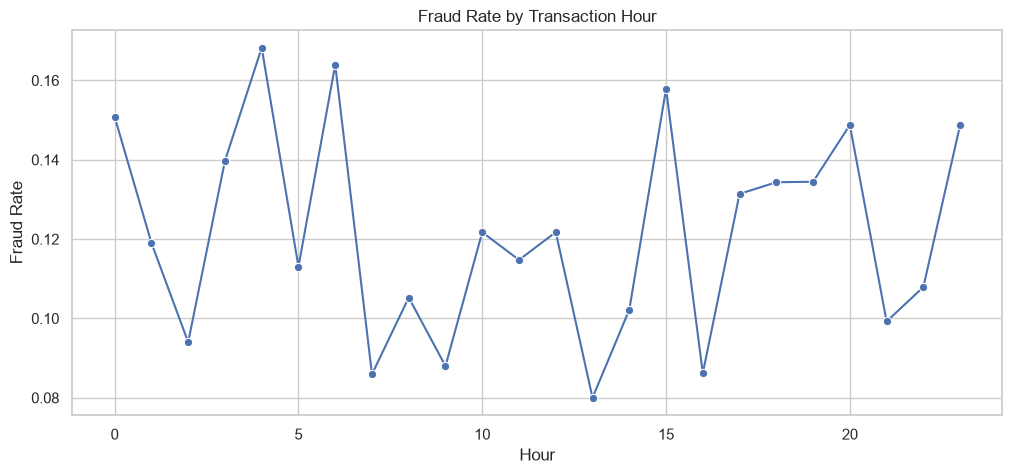

In [14]:
hourly_fraud = (
    df.groupby("hour")["fraud"]
    .mean()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hourly_fraud.index,
    y=hourly_fraud.values,
    marker="o"
)

plt.title("Fraud Rate by Transaction Hour")

plt.xlabel("Hour")
plt.ylabel("Fraud Rate")

plt.savefig(FIGURE_DIR / "11_hourly_fraud.png", dpi=300)
plt.show()

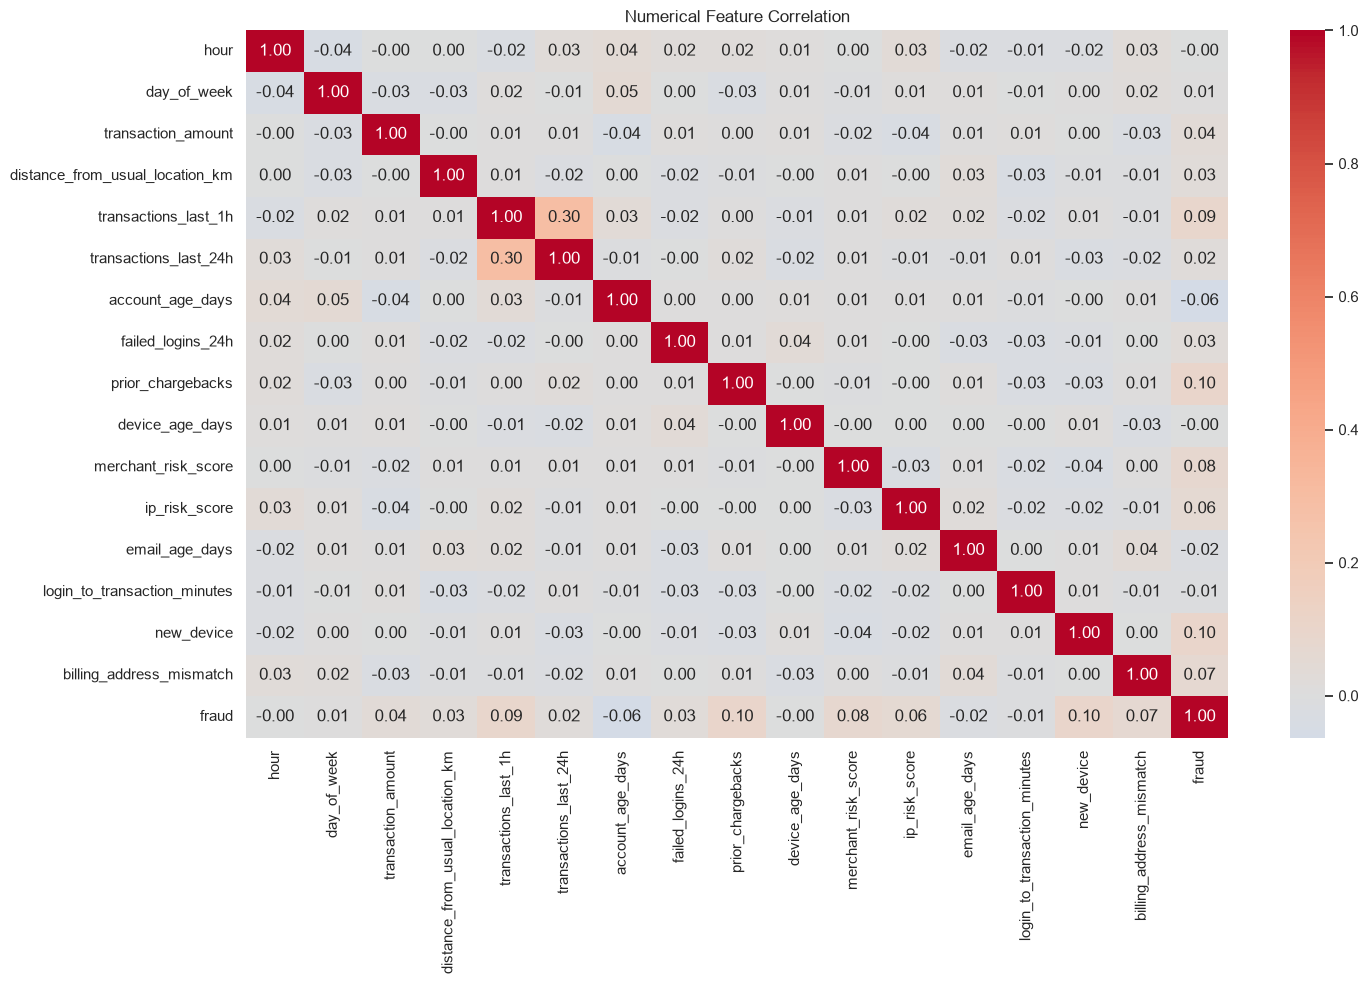

In [15]:
plt.figure(figsize=(15, 10))

numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Numerical Feature Correlation")

plt.tight_layout()

plt.savefig(FIGURE_DIR / "12_correlation_heatmap.png", dpi=300)
plt.show()

In [18]:
import sys
from pathlib import Path

# Add src directory to Python path
sys.path.insert(0, str(ROOT_DIR / "src"))

# Now import custom module
from feature_engineering import create_features

# Sklearn imports
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import average_precision_score
from sklearn.base import clone

In [20]:
def prepare_features(df):

    # Separate target variable
    X = df.drop(columns=["fraud"])

    # Identify numerical and categorical columns
    numerical_cols = X.select_dtypes(
        include=["int64", "float64"]
    ).columns.tolist()

    categorical_cols = X.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    # Numerical preprocessing
    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    # Categorical preprocessing
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    # Combine preprocessing pipelines
    preprocessor = ColumnTransformer([
        ("num", numerical_pipeline, numerical_cols),
        ("cat", categorical_pipeline, categorical_cols)
    ])

    return X, preprocessor

In [21]:
X = df.drop(columns=["fraud"])

In [22]:
numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

In [23]:
numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

In [24]:
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

In [28]:
X_original, prep_original = prepare_features(raw_df)

X_engineered, prep_engineered = prepare_features(engineered_df)

In [31]:
from sklearn.model_selection import train_test_split
import numpy as np

# Target variable
y_compare = raw_df["fraud"]

# Generate row indices
indices = np.arange(len(raw_df))

# Stratified train-validation split
train_idx, val_idx = train_test_split(
    indices,
    test_size=0.25,
    stratify=y_compare,
    random_state=42
)

print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))

Training samples: 2250
Validation samples: 750


In [32]:
preprocessor = prep_engineered

X_train = X_engineered.iloc[train_idx]

y_train = y_compare.iloc[train_idx]

In [33]:
X_val = X_engineered.iloc[val_idx]

y_val = y_compare.iloc[val_idx]

In [34]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

print("\nTraining fraud distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation fraud distribution:")
print(y_val.value_counts(normalize=True))

X_train shape: (2250, 41)
y_train shape: (2250,)
X_val shape: (750, 41)
y_val shape: (750,)

Training fraud distribution:
fraud
0    0.878667
1    0.121333
Name: proportion, dtype: float64

Validation fraud distribution:
fraud
0    0.878667
1    0.121333
Name: proportion, dtype: float64
